# Human Activity Recognition from Wearable Inertial Sensors

**IT8414 — Deep Learning for Data Analytics · Assessment 2: Group Project**

Group [NN] · [member names and IDs] · Tutor: Dr. Shomona Jacob

---

Six-class classification of human activity — walking, walking upstairs, walking
downstairs, sitting, standing and laying — from 2.56-second windows of
accelerometer and gyroscope signal recorded by a waist-worn smartphone.

We use the **raw inertial signals** (9 channels × 128 timesteps per window), not
the 561 hand-engineered features that ship alongside them. The pre-computed
features already encode a human's judgement of what matters in the signal;
feeding them to a network would leave the network with very little to learn.
Working from the raw waveform is what makes this a deep learning problem — the
convolutional filters have to discover the periodic structure of a footstep for
themselves.

Dataset provenance, licence and limitations: see `DATA.md`.

**How to run:** execute every cell top to bottom. Total runtime is a few minutes
on CPU. All behaviour is controlled by the `CONFIG` dictionary in section 1.0.

## 1.0 Setup

Imports, library versions, random seed and the single configuration block that
governs the rest of the notebook.

Everything tunable lives in `CONFIG`. No layer, optimiser or training parameter
is hardcoded further down — changing a value there and re-running is the only
way the notebook's behaviour changes. This keeps every experiment traceable to
one place.

In [1]:
# author: Ahmad Abbas
import json
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn

print(f"numpy       {np.__version__}")
print(f"pandas      {pd.__version__}")
print(f"torch       {torch.__version__}")
print(f"matplotlib  {matplotlib.__version__}")
print(f"sklearn     {sklearn.__version__}")

numpy       2.5.3
pandas      3.0.6
torch       2.14.0+cpu
matplotlib  3.11.2
sklearn     1.9.1


### Reproducibility

The brief requires a fixed seed. One function seeds all three sources of
randomness the notebook touches:

- `random` — Python's own generator.
- `numpy` — the subject-wise split draw in section 4.0.
- `torch` — weight initialisation and `DataLoader` shuffling.

`cudnn.deterministic` is set for completeness. It has no effect on CPU, but it
means a run on a GPU machine reproduces the same numbers rather than silently
selecting a faster non-deterministic convolution algorithm.

Seeding fixes *initialisation and shuffling order*. It does not by itself make
two architectures comparable — that also requires holding the data splits
constant, which section 4.0 does.

In [2]:
# author: Ahmad Abbas
def set_seed(seed):
    """Seed every generator the notebook uses, so a re-run reproduces exactly."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

### Configuration

Every value the tutor might ask us to change during the live demonstration is
here, named, in one cell.

`activation`, `dropout`, `kernel_size` and `conv_width` are read by the model
builders in sections 5.0 and 6.0. `optimizer`, `loss`, `learning_rate`,
`batch_size`, `epochs` and `patience` are read by the shared training function.
Nothing below re-declares them.

In [3]:
# author: Ahmad Abbas
CONFIG = {
    # Reproducibility
    "seed": 42,

    # Data and splitting
    "n_val_subjects": 6,      # held out from the 21 training subjects, BY SUBJECT
    "batch_size": 64,

    # Model architecture
    "activation": "relu",     # relu | leaky_relu | tanh | elu
    "dropout": 0.3,           # 0.0 disables dropout entirely
    "conv_width": 64,         # channels per convolutional block
    "kernel_size": 5,         # temporal kernel width

    # Training
    "optimizer": "adam",      # adam | sgd | rmsprop
    "loss": "cross_entropy",
    "learning_rate": 1e-3,
    "epochs": 30,
    "patience": 8,            # early stopping: epochs without val-loss improvement
}

set_seed(CONFIG["seed"])

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")
print(json.dumps(CONFIG, indent=2))

device: cpu
{
  "seed": 42,
  "n_val_subjects": 6,
  "batch_size": 64,
  "activation": "relu",
  "dropout": 0.3,
  "conv_width": 64,
  "kernel_size": 5,
  "optimizer": "adam",
  "loss": "cross_entropy",
  "learning_rate": 0.001,
  "epochs": 30,
  "patience": 8
}


### Paths and figure handling

Figures are written to `figures/` as well as displayed inline, so the report can
reference exactly the files the notebook produced. Every figure is numbered in
its filename and captioned in its title.

In [4]:
# author: Ahmad Abbas
REPO = Path.cwd()
DATA_DIR = REPO / "data" / "UCI HAR Dataset"
FIG_DIR = REPO / "figures"
MODEL_DIR = REPO / "models"
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

assert DATA_DIR.exists(), f"Dataset not found at {DATA_DIR}. Run: python scripts/get_data.py"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})


def savefig(fig, number, slug):
    """Save a numbered figure to figures/ and report the path."""
    path = FIG_DIR / f"fig{number:02d}_{slug}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"saved {path.relative_to(REPO)}")

## 2.0 Data loading

Each window is a 2.56-second recording at 50 Hz — 128 readings — across nine
sensor channels. The nine channels arrive as nine separate text files per split,
each with one window per row, so loading means stacking them into a
`(n_windows, 9, 128)` array.

That channel-first layout is deliberate: PyTorch's `Conv1d` expects
`(batch, channels, length)`, so the array feeds the model without transposition.

### Why all nine channels are kept

The three groups are not independent — `total_acc = body_acc + gravity`, so
`total_acc` carries no new information in a strict sense. We keep it anyway. The
gravity component encodes **device orientation**, and orientation is the main
thing separating the three static postures, none of which produces much body
acceleration. Section 3.3 measures this directly.

Loading takes about two seconds, so there is no caching layer. Reading the files
each run is simpler than maintaining a cache and cannot go stale.

In [5]:
# author: Ahmad Abbas
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]

ACTIVITIES = [
    "WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS",
    "SITTING", "STANDING", "LAYING",
]

SAMPLING_HZ = 50
WINDOW_LEN = 128           # 2.56 s at 50 Hz
N_CLASSES = len(ACTIVITIES)
N_CHANNELS = len(CHANNELS)

In [6]:
# author: Ahmad Abbas
def load_split(split):
    """Load one official split.

    Returns
    -------
    X : float32 (n_windows, 9, 128)   channel-first, ready for Conv1d
    y : int64   (n_windows,)          class index 0-5
    subjects : int (n_windows,)       volunteer ID who produced each window
    """
    signals = [
        np.loadtxt(DATA_DIR / split / "Inertial Signals" / f"{ch}_{split}.txt",
                   dtype=np.float32)
        for ch in CHANNELS
    ]
    X = np.stack(signals, axis=1)
    # Labels ship as 1-6; PyTorch cross-entropy expects 0-based indices.
    y = np.loadtxt(DATA_DIR / split / f"y_{split}.txt", dtype=np.int64) - 1
    subjects = np.loadtxt(DATA_DIR / split / f"subject_{split}.txt", dtype=int)
    return X, y, subjects

In [7]:
# author: Ahmad Abbas
t0 = time.time()
X_trainval, y_trainval, subj_trainval = load_split("train")
X_test, y_test, subj_test = load_split("test")
print(f"loaded in {time.time() - t0:.1f}s\n")

print(f"train+val : X{X_trainval.shape}  y{y_trainval.shape}  "
      f"{len(np.unique(subj_trainval))} subjects")
print(f"test      : X{X_test.shape}  y{y_test.shape}  "
      f"{len(np.unique(subj_test))} subjects")

overlap = set(subj_trainval.tolist()) & set(subj_test.tolist())
print(f"\nsubjects appearing in both official splits: {overlap or 'none'}")

loaded in 1.8s

train+val : X(7352, 9, 128)  y(7352,)  21 subjects
test      : X(2947, 9, 128)  y(2947,)  9 subjects

subjects appearing in both official splits: none


## 3.0 Exploratory data analysis

Five figures. Each exists to settle a specific decision made later in the
notebook:

| Figure | Question it answers | Decision it drives |
|---|---|---|
| 1 | How balanced are the classes? | Whether the loss needs class weighting (§5.2) |
| 2 | What does each activity look like? | Which channels carry the signal |
| 3 | What separates the classes numerically? | Keeping `total_acc`; normalise per channel, not per window (§4.2) |
| 4 | What is the dominant timescale? | Receptive field, hence network depth (§5.1) |
| 5 | Do neighbouring windows share data? | Splitting by subject rather than by window (§4.1) |

All exploration is done on the **training split only**. Looking at the test set
to inform design decisions is a form of leakage — the test set has to stay
untouched until section 8.0 for its measurement to mean anything.

### 3.1 Class distribution

saved figures\fig01_class_distribution.png


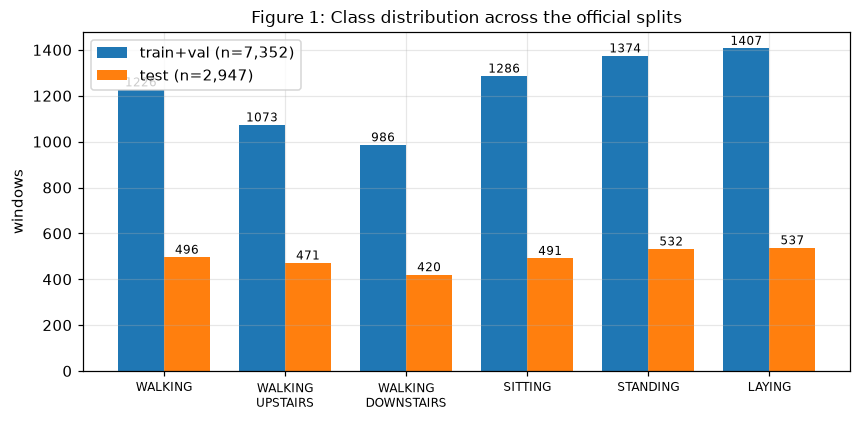


train+val imbalance ratio (largest/smallest): 1.43x
  largest : LAYING (1407)
  smallest: WALKING_DOWNSTAIRS (986)


In [8]:
# author: Ahmad Abbas
counts_tr = np.bincount(y_trainval, minlength=N_CLASSES)
counts_te = np.bincount(y_test, minlength=N_CLASSES)

fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(N_CLASSES)
w = 0.38
ax.bar(idx - w / 2, counts_tr, w, label=f"train+val (n={counts_tr.sum():,})")
ax.bar(idx + w / 2, counts_te, w, label=f"test (n={counts_te.sum():,})")
for i, (a, b) in enumerate(zip(counts_tr, counts_te)):
    ax.text(i - w / 2, a + 15, str(a), ha="center", fontsize=8)
    ax.text(i + w / 2, b + 15, str(b), ha="center", fontsize=8)
ax.set_xticks(idx)
ax.set_xticklabels([a.replace("_", "\n") for a in ACTIVITIES], fontsize=8)
ax.set_ylabel("windows")
ax.set_title("Figure 1: Class distribution across the official splits")
ax.legend()
savefig(fig, 1, "class_distribution")
plt.show()

ratio = counts_tr.max() / counts_tr.min()
print(f"\ntrain+val imbalance ratio (largest/smallest): {ratio:.2f}x")
print(f"  largest : {ACTIVITIES[counts_tr.argmax()]} ({counts_tr.max()})")
print(f"  smallest: {ACTIVITIES[counts_tr.argmin()]} ({counts_tr.min()})")

**Interpretation.** The imbalance ratio is about 1.4:1 — the largest class has
roughly 40% more windows than the smallest, and the same shape appears in both
splits. This is mild. A naive classifier that always predicted the majority
class would reach only about 19% accuracy, not the 90%+ that severe imbalance
produces.

**Decision:** train with plain unweighted `CrossEntropyLoss`. Class weighting
would add a hyperparameter to defend for a problem the data does not have.

This does **not** mean accuracy is a safe metric here. It means the reason to
distrust accuracy is a different one — errors turn out to concentrate in a
single confusable pair, which figure 3 predicts and section 8.0 confirms. A
model can score well overall while failing systematically on one class, and
accuracy alone will not show it.

### 3.2 What each activity looks like

One representative window per activity. We plot body acceleration magnitude
(gravity removed, so this is motion only) alongside gyroscope magnitude
(rotation), reducing the nine channels to two interpretable quantities.

saved figures\fig02_example_windows.png


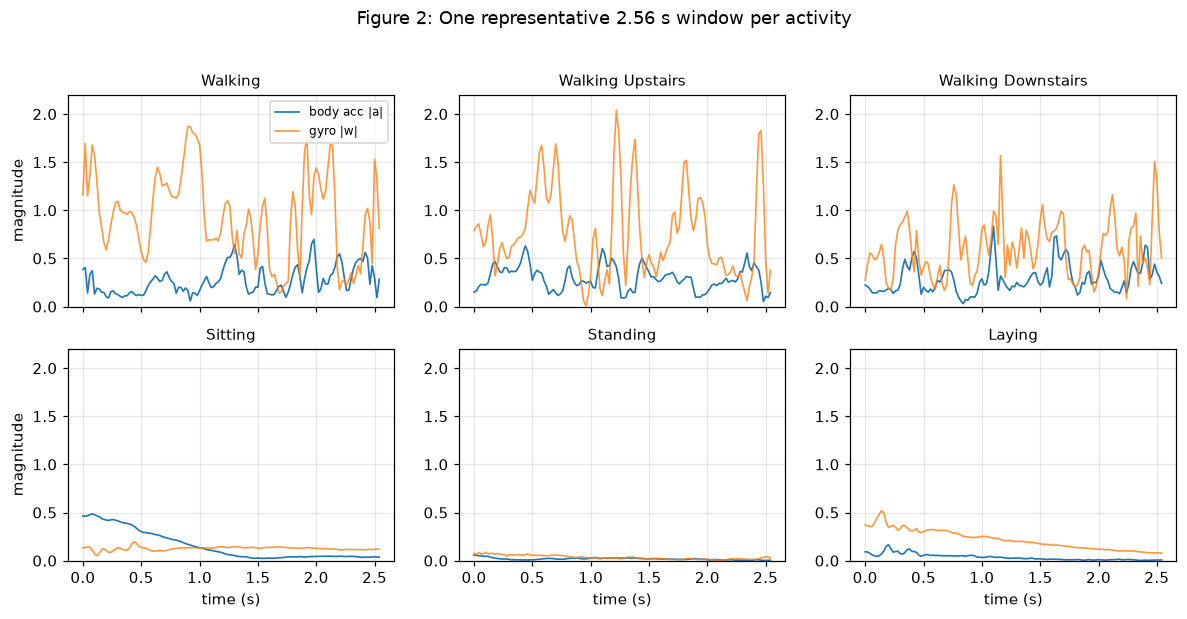

In [9]:
# author: Ahmad Abbas
def magnitude(X, start):
    """Euclidean magnitude of the 3-axis group beginning at channel `start`."""
    return np.linalg.norm(X[:, start:start + 3], axis=1)

body_mag_tr = magnitude(X_trainval, 0)    # body_acc  x,y,z -> channels 0:3
gyro_mag_tr = magnitude(X_trainval, 3)    # body_gyro x,y,z -> channels 3:6

t = np.arange(WINDOW_LEN) / SAMPLING_HZ

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for k, ax in enumerate(axes.ravel()):
    i = np.flatnonzero(y_trainval == k)[0]          # first window of this class
    ax.plot(t, body_mag_tr[i], lw=1.1, label="body acc |a|")
    ax.plot(t, gyro_mag_tr[i], lw=1.1, alpha=0.8, label="gyro |w|")
    ax.set_title(ACTIVITIES[k].replace("_", " ").title(), fontsize=10)
    ax.set_ylim(0, 2.2)
    if k >= 3:
        ax.set_xlabel("time (s)")
    if k % 3 == 0:
        ax.set_ylabel("magnitude")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Figure 2: One representative 2.56 s window per activity", y=1.02)
savefig(fig, 2, "example_windows")
plt.show()

**Interpretation.** Two regimes are visible by eye.

The three walking activities show strong, roughly periodic oscillation in both
acceleration and rotation — each peak is a footstep. The three static postures
are nearly flat lines close to zero: sitting, standing and laying all involve
almost no body acceleration and almost no rotation.

Plotted this way, **sitting, standing and laying are almost indistinguishable
from one another.** That is the central difficulty of this problem, and it is
not a rendering artefact — these channels genuinely do not separate the static
classes. Something else has to, which is what figure 3 looks for.

### 3.3 What actually separates the classes

Figure 2 suggests two quantities worth measuring per window:

- **Dynamic energy** — the standard deviation of body acceleration magnitude
  within the window. High while moving, near zero while still.
- **Orientation** — the mean gravity vector. Gravity is recoverable as
  `total_acc − body_acc`, and its direction tells us how the device was tilted,
  which is a proxy for body posture.

Orientation is the only thing that can separate the static postures, since by
definition they have no motion to measure.

saved figures\fig03_separability.png


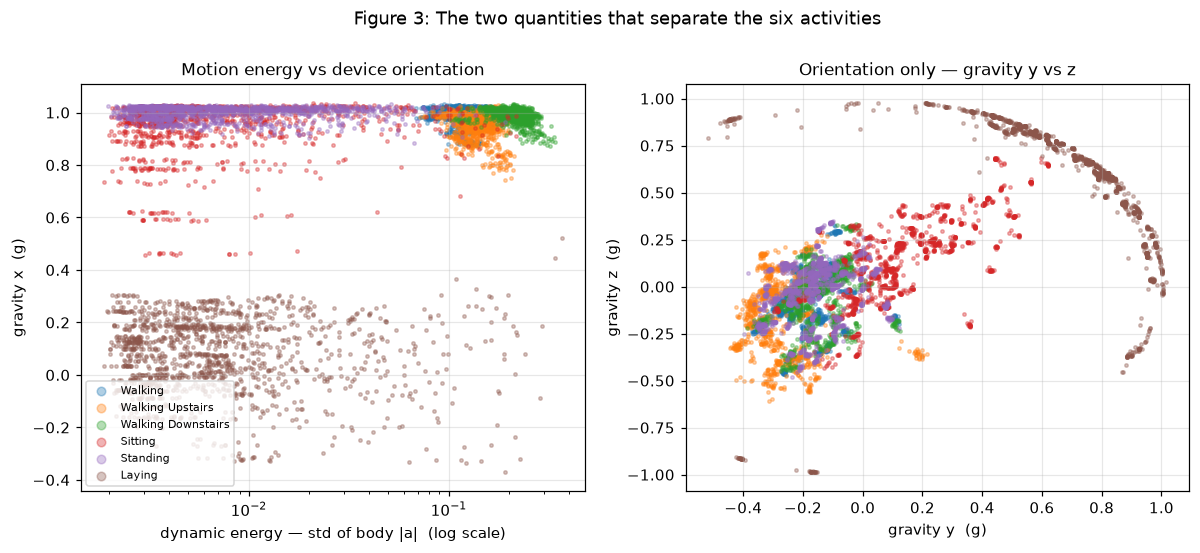

In [10]:
# author: Ahmad Abbas
gravity_tr = X_trainval[:, 6:9] - X_trainval[:, 0:3]     # total_acc - body_acc
grav_mean_tr = gravity_tr.mean(axis=2)                   # (n, 3) per-window mean
dynamic_energy_tr = body_mag_tr.std(axis=1)              # (n,)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))

for k in range(N_CLASSES):
    m = y_trainval == k
    ax1.scatter(dynamic_energy_tr[m], grav_mean_tr[m, 0], s=5, alpha=0.35,
                color=colors[k], label=ACTIVITIES[k].replace("_", " ").title())
ax1.set_xscale("log")
ax1.set_xlabel("dynamic energy — std of body |a|  (log scale)")
ax1.set_ylabel("gravity x  (g)")
ax1.set_title("Motion energy vs device orientation")
ax1.legend(fontsize=7, markerscale=2.5, loc="lower left")

for k in range(N_CLASSES):
    m = y_trainval == k
    ax2.scatter(grav_mean_tr[m, 1], grav_mean_tr[m, 2], s=5, alpha=0.35, color=colors[k])
ax2.set_xlabel("gravity y  (g)")
ax2.set_ylabel("gravity z  (g)")
ax2.set_title("Orientation only — gravity y vs z")

fig.suptitle("Figure 3: The two quantities that separate the six activities", y=1.02)
savefig(fig, 3, "separability")
plt.show()

In [11]:
# author: Ahmad Abbas
rows = []
for k in range(N_CLASSES):
    m = y_trainval == k
    g = grav_mean_tr[m].mean(axis=0)
    rows.append({
        "activity": ACTIVITIES[k],
        "dyn_energy": dynamic_energy_tr[m].mean(),
        "grav_x": g[0], "grav_y": g[1], "grav_z": g[2],
    })
summary = pd.DataFrame(rows).set_index("activity").round(3)
print(summary.to_string())

# How far apart are the static postures in orientation space?
static = {a: summary.loc[a, ["grav_x", "grav_y", "grav_z"]].to_numpy(float)
          for a in ("SITTING", "STANDING", "LAYING")}
print("\nEuclidean distance between static postures in gravity space (g):")
for a, b in (("SITTING", "STANDING"), ("SITTING", "LAYING"), ("STANDING", "LAYING")):
    print(f"  {a:8} <-> {b:8} {np.linalg.norm(static[a] - static[b]):.3f}")

dyn = summary["dyn_energy"]
print(f"\nclass-mean dynamic energy:"
      f" moving {dyn.iloc[:3].min():.4f}-{dyn.iloc[:3].max():.4f}"
      f"  vs static {dyn.iloc[3:].min():.4f}-{dyn.iloc[3:].max():.4f}"
      f"   ({dyn.iloc[:3].min() / dyn.iloc[3:].max():.0f}x gap between means)")

# Class means are far apart, but do the individual windows actually separate?
moving = dynamic_energy_tr[y_trainval < 3]
static = dynamic_energy_tr[y_trainval >= 3]
n_above = int((static > moving.min()).sum())
print(f"\nper-window ranges (not means):")
print(f"  moving: {moving.min():.4f} - {moving.max():.4f}")
print(f"  static: {static.min():.4f} - {static.max():.4f}")
print(f"  static windows exceeding the quietest moving window: "
      f"{n_above}/{len(static)} ({100 * n_above / len(static):.1f}%)")

                    dyn_energy  grav_x  grav_y  grav_z
activity                                              
WALKING                  0.125   0.996  -0.181  -0.069
WALKING_UPSTAIRS         0.142   0.953  -0.268  -0.151
WALKING_DOWNSTAIRS       0.212   0.989  -0.149  -0.057
SITTING                  0.013   0.952   0.141   0.154
STANDING                 0.011   1.001  -0.164  -0.032
LAYING                   0.016   0.073   0.650   0.560

Euclidean distance between static postures in gravity space (g):
  SITTING  <-> STANDING 0.361
  SITTING  <-> LAYING   1.094
  STANDING <-> LAYING   1.369

class-mean dynamic energy: moving 0.1250-0.2120  vs static 0.0110-0.0160   (8x gap between means)

per-window ranges (not means):
  moving: 0.0584 - 0.3391
  static: 0.0019 - 0.3686
  static windows exceeding the quietest moving window: 166/4067 (4.1%)


**Interpretation.** Three findings, each with a consequence.

**1. Moving versus still is easy, but not perfectly.** The class *means* differ
by roughly an order of magnitude — around 0.13–0.21 for the walking activities
against 0.011–0.016 for the static ones.

The per-window ranges tell a more careful story: the distributions overlap at
the tails, with about 4% of static windows registering more energy than the
quietest moving window. Those are most likely windows containing a small
postural adjustment — a shift in the chair, a lean. So while the boundary is
easy on average, we should expect a handful of static-to-moving errors rather
than none, and section 8.5 checks whether the misclassified windows look like
this.

**2. Sitting and standing are the hard pair — and we can say how hard.** In
gravity space, sitting and standing sit about **0.36 g** apart, while sitting and
laying are about **1.09 g** apart: three times further. Laying tips the device
almost onto its side (gravity x drops from ≈1.0 to ≈0.07), an unmistakable
signature. Sitting and standing differ only by the modest forward tilt of the
waist when seated, and the right-hand panel shows their clouds genuinely
overlapping.

This is a concrete, falsifiable prediction: **the confusion matrix in section
8.0 should show its largest off-diagonal mass between sitting and standing.**
We will check it there.

**3. `total_acc` is load-bearing.** Orientation is computed from
`total_acc − body_acc`. Drop `total_acc` and the gravity component goes with it,
leaving nothing to distinguish three of the six classes. This is why section
2.0 keeps all nine channels despite the algebraic redundancy.

**Decision (§4.2):** standardise **per channel across the whole training set**,
never per window. Per-window normalisation subtracts each window's own mean,
which removes exactly the constant gravity offset that carries orientation. It
is a common default and it would silently destroy the only signal separating
sitting, standing and laying.

### 3.4 Dominant timescale

A convolutional filter can only detect a pattern that fits inside its receptive
field. To size the network we need to know the timescale of the structure it
must capture, so we take the magnitude spectrum of body acceleration and find
the dominant frequency per activity.

At 50 Hz over 128 samples the resolution is 50/128 ≈ 0.39 Hz, with a Nyquist
limit of 25 Hz. The DC bin is removed first — we want periodicity, not mean
level.

saved figures\fig04_frequency_spectra.png


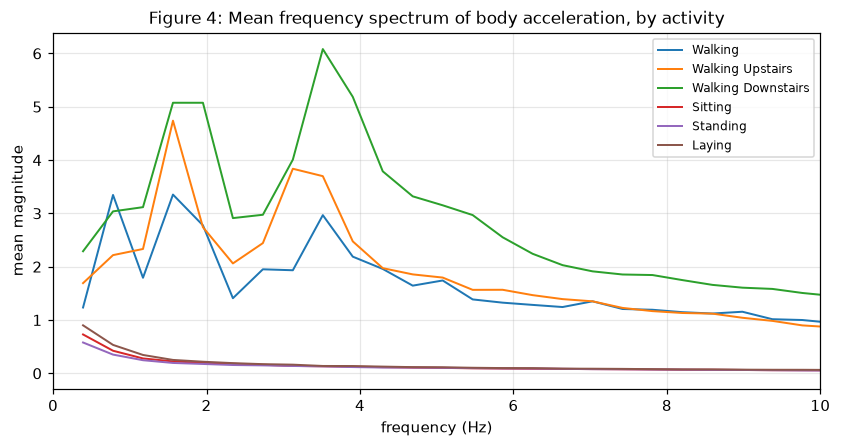

activity                peak Hz  period s  period in samples
WALKING                    1.56      0.64                 32
WALKING_UPSTAIRS           1.56      0.64                 32
WALKING_DOWNSTAIRS         3.52      0.28                 14
SITTING                    0.39      2.56                128
STANDING                   0.39      2.56                128
LAYING                     0.39      2.56                128


In [12]:
# author: Ahmad Abbas
freqs = np.fft.rfftfreq(WINDOW_LEN, d=1 / SAMPLING_HZ)
centred = body_mag_tr - body_mag_tr.mean(axis=1, keepdims=True)   # drop DC
spectra = np.abs(np.fft.rfft(centred, axis=1))

fig, ax = plt.subplots(figsize=(9, 4.2))
peaks = {}
for k in range(N_CLASSES):
    mean_spec = spectra[y_trainval == k].mean(axis=0)
    ax.plot(freqs[1:], mean_spec[1:], lw=1.3, color=colors[k],
            label=ACTIVITIES[k].replace("_", " ").title())
    peaks[ACTIVITIES[k]] = freqs[1:][mean_spec[1:].argmax()]
ax.set_xlim(0, 10)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("mean magnitude")
ax.set_title("Figure 4: Mean frequency spectrum of body acceleration, by activity")
ax.legend(fontsize=8)
savefig(fig, 4, "frequency_spectra")
plt.show()

print(f"{'activity':22} {'peak Hz':>8} {'period s':>9} {'period in samples':>18}")
for a, f in peaks.items():
    print(f"{a:22} {f:8.2f} {1 / f:9.2f} {SAMPLING_HZ / f:18.0f}")

**Interpretation.** Walking and walking upstairs peak near **1.56 Hz** — a
period of 0.64 s, or **32 samples**. Walking downstairs peaks higher, near
3.5 Hz (about 14 samples), consistent with the quicker, harder footfalls of
descending. The static postures show no peak at all: their maximum sits in the
lowest resolvable bin, which is the spectrum's way of saying "no periodicity
here".

**Decision (§5.1):** the network needs a receptive field of **at least 32
samples** for a filter to see one complete gait cycle. This sets the depth.
With kernel size 5 and 2× pooling between blocks, two convolutional blocks
reach a receptive field of 16 samples — enough for a downstairs step, too short
for a walking stride. A third block extends it to 36. That is why the baseline
in section 5.0 has three convolutional blocks rather than two: the number comes
from this measurement, not from a default.

### 3.5 Window overlap, and why it dictates the split

The dataset documentation states that windows were cut with 50% overlap. That
has a direct consequence for how we are allowed to split the data, so rather
than taking it on trust we verify it on the array itself.

If the claim holds, the second half of one window is byte-for-byte the first
half of the next.

windows 0 and 1: subject 1, STANDING
second half of window 0 == first half of window 1: True
max absolute difference over the shared region: 0.00e+00
saved figures\fig05_window_overlap.png


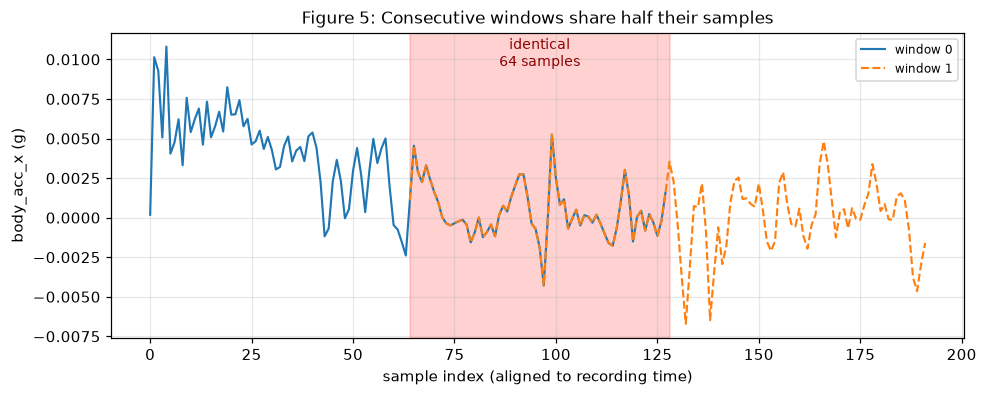

In [13]:
# author: Ahmad Abbas
# Find the first pair of consecutive rows from the same subject and activity.
i = next(j for j in range(len(y_trainval) - 1)
         if subj_trainval[j] == subj_trainval[j + 1] and y_trainval[j] == y_trainval[j + 1])

a, b = X_trainval[i, 0], X_trainval[i + 1, 0]        # body_acc_x of each window
shared = np.allclose(a[64:], b[:64], atol=1e-6)
print(f"windows {i} and {i + 1}: subject {subj_trainval[i]}, "
      f"{ACTIVITIES[y_trainval[i]]}")
print(f"second half of window {i} == first half of window {i + 1}: {shared}")
print(f"max absolute difference over the shared region: "
      f"{np.abs(a[64:] - b[:64]).max():.2e}")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(np.arange(128), a, lw=1.4, label=f"window {i}")
ax.plot(np.arange(64, 192), b, lw=1.4, ls="--", label=f"window {i + 1}")
ax.axvspan(64, 128, alpha=0.18, color="red")
ax.text(96, ax.get_ylim()[1] * 0.82, "identical\n64 samples",
        ha="center", fontsize=9, color="darkred")
ax.set_xlabel("sample index (aligned to recording time)")
ax.set_ylabel("body_acc_x (g)")
ax.set_title("Figure 5: Consecutive windows share half their samples")
ax.legend(fontsize=8)
savefig(fig, 5, "window_overlap")
plt.show()

**Interpretation.** Confirmed exactly — the overlapping region is identical to
within floating-point tolerance.

This makes the obvious split strategy unusable. Shuffling all 7,352 windows and
taking a random 20% for validation would place window *i* in training and window
*i+1* in validation while **64 of their 128 readings are the same numbers**. The
validation score would then be partly a measure of memorisation, and it would
look good.

Subject identity makes it worse. Even windows that share no samples share a
person's gait: their stride length, their cadence, how they carry their weight.
A model can learn to recognise *this particular person walking* and score
highly, while being unable to recognise walking in anyone new. That is the
opposite of what a deployed activity monitor needs, since it meets users it has
never seen.

**Decision (§4.1):** split **by subject**, never by window. The official test
set is already subject-disjoint, so we preserve that and carve validation out of
the training subjects the same way. Section 7.0 quantifies what the shortcut
would have bought us, by training the same model under a random window split and
reporting both numbers side by side.

### 3.6 What the EDA decided

| Finding | Evidence | Consequence |
|---|---|---|
| Imbalance is mild (≈1.4:1) | Figure 1 | Unweighted `CrossEntropyLoss` (§5.2) |
| Static postures are flat in motion channels | Figure 2 | Motion alone cannot separate them |
| Orientation separates static postures; sitting/standing only 0.36 g apart | Figure 3 | Keep all 9 channels; expect sitting↔standing confusion (§8.0) |
| Per-window normalisation would erase the gravity offset | Figure 3 | Standardise per channel over the training set (§4.2) |
| Gait period ≈ 32 samples | Figure 4 | Receptive field ≥ 32 → three conv blocks (§5.1) |
| Consecutive windows share 64/128 samples | Figure 5 | Split by subject, not by window (§4.1) |

## 4.0 Preprocessing and splitting

Three steps, in an order that matters:

1. Split the 21 training subjects into train and validation **by subject**.
2. Compute normalisation statistics **on the training subjects only**, then
   apply them everywhere.
3. Wrap the arrays as tensors and `DataLoader`s.

Doing step 1 before step 2 is the whole point. Computing the mean and standard
deviation over all the data and splitting afterwards would let information from
the validation and test subjects influence how the training data is scaled — a
subtle leak that inflates results without ever looking like a bug.

Each step ends with an assertion. If a future edit reintroduces leakage, the
notebook fails loudly instead of quietly reporting a better number.

### 4.1 Subject-wise train/validation split

Section 3.5 established that splitting by window leaks. We hold out
`CONFIG["n_val_subjects"]` of the 21 training subjects entirely — every window
from a held-out subject goes to validation, and none of their data is ever
trained on.

The draw is seeded, so the split is reproducible and not cherry-picked. The
official test subjects are not touched here at all.

In [14]:
# author: Ahmad Abbas
train_subject_pool = np.unique(subj_trainval)
rng = np.random.default_rng(CONFIG["seed"])
val_subjects = np.sort(rng.choice(train_subject_pool,
                                  size=CONFIG["n_val_subjects"], replace=False))
train_subjects = np.setdiff1d(train_subject_pool, val_subjects)

train_mask = np.isin(subj_trainval, train_subjects)
val_mask = np.isin(subj_trainval, val_subjects)

X_train_raw, y_train, subj_train = X_trainval[train_mask], y_trainval[train_mask], subj_trainval[train_mask]
X_val_raw,   y_val,   subj_val   = X_trainval[val_mask],   y_trainval[val_mask],   subj_trainval[val_mask]
X_test_raw = X_test

print(f"train      {len(train_subjects):2d} subjects {train_subjects.tolist()}")
print(f"           {len(y_train):5d} windows")
print(f"validation {len(val_subjects):2d} subjects {val_subjects.tolist()}")
print(f"           {len(y_val):5d} windows")
print(f"test       {len(np.unique(subj_test)):2d} subjects {np.unique(subj_test).tolist()}")
print(f"           {len(y_test):5d} windows")

train      15 subjects [1, 5, 6, 7, 8, 11, 14, 16, 17, 21, 23, 25, 26, 27, 30]
            5276 windows
validation  6 subjects [3, 15, 19, 22, 28, 29]
            2076 windows
test        9 subjects [2, 4, 9, 10, 12, 13, 18, 20, 24]
            2947 windows


In [15]:
# author: Ahmad Abbas
# The guarantee this whole section exists to provide: no subject in two splits.
s_tr, s_va, s_te = set(subj_train.tolist()), set(subj_val.tolist()), set(subj_test.tolist())
assert not (s_tr & s_va), f"subject leak train/val: {s_tr & s_va}"
assert not (s_tr & s_te), f"subject leak train/test: {s_tr & s_te}"
assert not (s_va & s_te), f"subject leak val/test: {s_va & s_te}"
assert len(y_train) + len(y_val) == len(y_trainval), "windows lost in the split"
print("no subject appears in more than one split")
print(f"windows accounted for: {len(y_train)} + {len(y_val)} = {len(y_trainval)}")

no subject appears in more than one split
windows accounted for: 5276 + 2076 = 7352


#### Does the split stay balanced?

Holding out whole subjects means we cannot also stratify by class — we take
whichever activities those six people happened to perform. Worth checking that
the draw did not produce a lopsided validation set.

In [16]:
# author: Ahmad Abbas
dist = pd.DataFrame({
    "train": np.bincount(y_train, minlength=N_CLASSES),
    "val": np.bincount(y_val, minlength=N_CLASSES),
    "test": np.bincount(y_test, minlength=N_CLASSES),
}, index=ACTIVITIES)
pct = (dist / dist.sum() * 100).round(1)
print(pd.concat({"windows": dist, "% of split": pct}, axis=1).to_string())

# Per class, how much does its share differ across the three splits?
# (axis=1 compares a class across splits; axis=0 would compare classes within
#  a split, which measures imbalance rather than split consistency.)
spread = (pct.max(axis=1) - pct.min(axis=1)).round(1)
print("\nclass share, largest gap across the three splits (pp):")
print(spread.to_string())
print(f"\nworst case: {spread.max():.1f} percentage points ({spread.idxmax()})")
assert (dist > 0).all().all(), "a class is missing from a split"
print("every class is present in every split")

                   windows           % of split            
                     train  val test      train   val  test
WALKING                909  317  496       17.2  15.3  16.8
WALKING_UPSTAIRS       784  289  471       14.9  13.9  16.0
WALKING_DOWNSTAIRS     726  260  420       13.8  12.5  14.3
SITTING                908  378  491       17.2  18.2  16.7
STANDING               980  394  532       18.6  19.0  18.1
LAYING                 969  438  537       18.4  21.1  18.2

class share, largest gap across the three splits (pp):
WALKING               1.9
WALKING_UPSTAIRS      2.1
WALKING_DOWNSTAIRS    1.8
SITTING               1.5
STANDING              0.9
LAYING                2.9

worst case: 2.9 percentage points (LAYING)
every class is present in every split


**Interpretation.** All six activities appear in all three splits, and each
class holds a similar share of every split — the spread is a few percentage
points, which is what a subject-level draw over six people should produce.

The validation set is small enough that its estimates will be noisier than the
test set's. That is the price of an honest subject-wise split, and it is the
right trade: a noisy honest estimate is more useful for model selection than a
precise optimistic one.

### 4.2 Per-channel standardisation

Each channel is standardised to zero mean and unit variance using statistics
computed **across the training windows only**, then applied unchanged to
validation and test.

The channels arrive on different physical scales — acceleration in g,
angular velocity in rad/s — and the gyroscope varies roughly three to four times
as widely as body acceleration. Left alone, gradients from the wider channels
would dominate early training simply because their numbers are larger.

**The statistic is computed over `(windows, time)` per channel, not per window.**
Section 3.3 showed why: a per-window mean subtraction would remove each window's
own constant offset, and that offset *is* the gravity component carrying device
orientation — the only thing separating sitting, standing and laying. The
common default would quietly delete the signal for half the classes.

In [17]:
# author: Ahmad Abbas
# Mean and std per channel, over training windows and timesteps -> shape (1, 9, 1)
channel_mean = X_train_raw.mean(axis=(0, 2), keepdims=True)
channel_std = X_train_raw.std(axis=(0, 2), keepdims=True)

print(f"{'channel':14} {'mean':>9} {'std':>9}")
for i, ch in enumerate(CHANNELS):
    print(f"{ch:14} {channel_mean[0, i, 0]:9.4f} {channel_std[0, i, 0]:9.4f}")


def standardise(X):
    """Apply the training-set statistics. Never recomputed per split."""
    return (X - channel_mean) / channel_std


X_train = standardise(X_train_raw)
X_val = standardise(X_val_raw)
X_test_std = standardise(X_test_raw)

channel             mean       std
body_acc_x       -0.0007    0.1890
body_acc_y       -0.0003    0.1229
body_acc_z       -0.0001    0.1119
body_gyro_x       0.0017    0.3913
body_gyro_y      -0.0012    0.3950
body_gyro_z      -0.0004    0.2644
total_acc_x       0.8142    0.4021
total_acc_y       0.0231    0.3781
total_acc_z       0.0780    0.3645


In [18]:
# author: Ahmad Abbas
# Training data should now be centred; val/test should be close but not exact -
# if they were exact, the statistics would have been fitted on them.
print(f"train mean {X_train.mean():+.6f}  std {X_train.std():.6f}   (expect 0.0 / 1.0)")
print(f"val   mean {X_val.mean():+.6f}  std {X_val.std():.6f}")
print(f"test  mean {X_test_std.mean():+.6f}  std {X_test_std.std():.6f}")

assert abs(X_train.mean()) < 1e-5 and abs(X_train.std() - 1) < 1e-5, \
    "training data is not standardised"
assert abs(X_val.mean()) > 1e-9, \
    "validation mean is exactly zero - statistics were fitted on validation data"
print("\nstatistics were fitted on training subjects only")

train mean +0.000000  std 1.000000   (expect 0.0 / 1.0)
val   mean +0.005106  std 1.002634
test  mean -0.006037  std 0.956263

statistics were fitted on training subjects only


**Interpretation.** Training data is exactly centred, as it must be. Validation
and test are *near* zero mean but not exactly — and that small residual offset is
the evidence that the statistics were not fitted on them. If validation had come
out at exactly zero mean, it would mean we had normalised using its own
statistics, which is leakage. The second assertion fails in precisely that case.

Note that the gravity offset is preserved: `total_acc_x` had a training mean
near 0.80 g before scaling, and standardisation subtracts that same constant
from every window rather than from each window individually. The *relative*
orientation differences between postures survive intact.

### 4.3 Tensors and data loaders

The arrays are already `(n, 9, 128)` — channel-first, which is what `Conv1d`
expects — so they convert directly with no transposition.

Only the training loader shuffles. Validation and test are evaluated in a fixed
order so that repeated evaluations of the same model give identical numbers, and
a larger batch size is used there because no gradients are stored.

In [19]:
# author: Ahmad Abbas
def make_loader(X, y, batch_size, shuffle):
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


set_seed(CONFIG["seed"])       # fix shuffling order for reproducibility
train_loader = make_loader(X_train, y_train, CONFIG["batch_size"], shuffle=True)
val_loader = make_loader(X_val, y_val, 256, shuffle=False)
test_loader = make_loader(X_test_std, y_test, 256, shuffle=False)

xb, yb = next(iter(train_loader))
print(f"batch: X {tuple(xb.shape)} {xb.dtype}   y {tuple(yb.shape)} {yb.dtype}")
print(f"batches per epoch: train {len(train_loader)}, "
      f"val {len(val_loader)}, test {len(test_loader)}")
assert xb.shape[1:] == (N_CHANNELS, WINDOW_LEN)
assert yb.min() >= 0 and yb.max() < N_CLASSES

batch: X (64, 9, 128) torch.float32   y (64,) torch.int64
batches per epoch: train 83, val 9, test 12


### 4.4 Preprocessing summary

| Step | Choice | Why |
|---|---|---|
| Representation | Raw 9 × 128 signals | Lets the network learn its own features (§2.0) |
| Missing values | None to handle | Dataset is complete; verified by shape checks |
| Split | By subject, seeded | Windows overlap 50% and carry personal gait (§3.5) |
| Validation | 6 of 21 training subjects | Held out entirely; test set untouched until §8.0 |
| Scaling | Per-channel z-score, fitted on train | Channels differ in unit and scale |
| Not done | Per-window normalisation | Would erase the gravity offset (§3.3) |
| Not done | Class weighting | Imbalance is only ≈1.4:1 (§3.1) |
| Not done | Augmentation | Deferred to §7.0, where it is tested as an experiment |

The data is now ready for modelling. Everything from here reads `train_loader`,
`val_loader` and `test_loader`, and no cell below section 4.0 touches the raw
arrays again.